# Revenant Conduit (Harakim)

Revenant Conduit is a toggled self buff. While it is open, the caster's Ghost Companion skill
counts as at least 30% higher when companions are statted (+150% at modified skill 300).
Existing companions are re-statted immediately. Every point of post-mitigation damage a
companion deals also heals the (player) owner for 10–50% of it. The conduit drains 1 endurance
per second for each live companion and closes when endurance runs out, when it expires after
360 s, or when the caster recasts it.

**Rebalanced.** The first pass replaced the old +30% steps every 10 skill points (cap at skill 50)
with a linear `30 + 6p/5` that capped at +150% at skill 100, and made the drain 1 endurance per
second per live companion (`owned_live_companion_count`, minimum 1).

**Rebalanced (mod-300 knee).** Top-rank players reach about modified skill 275–300, and the
linear curve was flat for that whole stretch. The boost now uses `skill_knee_300(p, 30, 150)`
(`revenant_conduit_boost_pct`): +30% at skill 0, +150% at modified skill 300, then half that slope
with no upper limit. Companion stats are already bounded by the template maxima in
`recompute_companion_stats`, so the boost needs no clamp of its own. The heal is still one third of
the boost, capped at 50%, so it now reaches 50% at skill 300 and stops there. The drain is
unchanged. The dotted "before" curves below show the skill-100 cap.

| | |
|---|---|
| Class | Harakim |
| Target | Self (affects owned ghost companions) |
| Cost | 17 mana (not divided by 3 for Harakim); needs at least 25 endurance but does not spend it |
| Upkeep | 1 endurance per second per live companion (at least 1) while open |
| Cooldown | none; recasting while open closes it (toggle) |
| Landing roll | none |
| Duration | 360 s, or until endurance reaches 0, the caster recasts it, or no companion is left |
| Effect | `boost = skill_knee_300(p, 30, 150)` %: `30 + ⌊2p/5⌋` up to 300, then `150 + ⌊(p−300)/5⌋`, no upper limit; companions are statted from `ghost·(100+boost)/100`; owner healed `clamp(⌊boost/3⌋, 0, 50)` % of companion damage |
| Source | `server/src/driver/skill/companion.rs::skill_revenant_conduit`, `revenant_conduit_boost_pct`, `recompute_companion_stats`; `skill_knee_300` in `server/src/driver/skill/common.rs`; drain and heal in `server/src/state/stats.rs` (`apply_revenant_conduit_heal`) |

---

# Formula

With $p$ the modified Revenant Conduit skill (negative treated as 0), $g$ the modified Ghost
Companion skill and $n$ the number of live companions:

$$
\text{boost} =
\begin{cases}
30 + \left\lfloor \tfrac{120p}{300} \right\rfloor & p \le 300 \\[4pt]
150 + \left\lfloor \tfrac{120(p-300)}{600} \right\rfloor & p > 300
\end{cases}\ \%
\qquad
\text{heal} = \operatorname{clamp}\!\left(\lfloor \text{boost}/3 \rfloor,\ 0,\ 50\right)\%
\qquad
\text{drain} = \max(1, n)\ \text{endurance/s}
$$

$$
g' = \left\lfloor \frac{g\,(100 + \text{boost})}{100} \right\rfloor
\qquad
\text{base} = \text{race}\!\left(\left\lfloor \tfrac{4g'}{11} \right\rfloor\right)
\qquad
\text{attribute} = \max\!\left(10,\ \min\!\left(\text{cap},\ \left\lfloor \tfrac{3\,\text{base}}{\text{attrib}[3]} \right\rfloor\right)\right)
\qquad
\text{HP} = \max(50,\ \min(\text{cap},\ 5\,\text{base}))
$$

Skills follow the attribute rule with the template's `skill[n][3]` divisor. The template caps
(`attrib[n][2]`, `skill[n][2]`, `hp[2]`) come from the `CT_COMPANION` template in the world
snapshot, so this notebook models the **uncapped** values with divisor 1, as the Rust test does.
Those caps are the only upper bound on what the boost can do.

| Quantity | Breakpoint |
|---|---|
| Floor | +30% boost, 10% heal at $p = 0$ |
| At the raise cap ($p$ 105) | +72%, 24% heal (before: +150%, 50%) |
| At $p$ 120 | +78%, 26% heal (before: +150%, 50%) |
| Endgame ($p$ 275–300) | +140% to +150%, 46–50% heal |
| Knee ($p$ 300) | +150%, 50% heal (before: reached at $p$ 100) |
| Beyond the knee | +160% at 350, +180% at 450; heal stays at 50% |
| Slope | +0.4% boost per point to 300, +0.2% after (before: +1.2% to 100, then flat) |
| Hard limit | none on the boost; heal capped at 50% from $p$ 300 |
| Upkeep | 17 mana, plus 360 endurance per companion for a full 360 s |

---

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import mag_model as mm

mm.apply_style()
P = mm.SKILL_RANGE
MANA_COST = 17
END_GATE = 25
DURATION_S = 360
GHOST_SWEEP = (50, 105, 120, 200)

# Model

In [2]:
def boost_pct(p):
    return mm.knee_300(p, 30, 150)


def heal_pct(p):
    return mm.clamp(mm.idiv(boost_pct(p), 3), 0, 50)


def drain_per_s(companions):
    return np.maximum(1, np.asarray(companions))


def open_seconds(endurance, companions):
    """Seconds the conduit stays open on a full `endurance` pool (capped by the 360 s duration)."""
    return np.minimum(DURATION_S, mm.idiv(endurance, drain_per_s(companions)))


# Before the mod-300 knee: linear to +150% at skill 100, then flat.
def old_boost_pct(p):
    return mm.clamp(30 + mm.idiv(np.asarray(p) * 6, 5), 30, 150)


def old_heal_pct(p):
    return mm.clamp(mm.idiv(old_boost_pct(p), 3), 0, 50)


def companion_base(ghost, boost=0, race="Harakim"):
    eff = np.asarray(ghost) * (100 + np.asarray(boost)) // 100
    return mm.spell_race_mod(mm.idiv(eff * 4, 11), race)


def companion_attrib(base, divisor=1):
    return np.maximum(10, mm.idiv(np.asarray(base) * 3, divisor))


def companion_hp(base):
    return np.maximum(50, np.asarray(base) * 5)


def heal_hp(companion_damage_hp, p):
    """HP the owner regains for `companion_damage_hp` HP of post-mitigation companion damage."""
    return np.asarray(companion_damage_hp) * heal_pct(p) / 100

# Validation

- `revenant_conduit_boosts_existing_companions_and_toggles_off`: Ghost 110, conduit skill 150 →
  boost 90, mana 50,000 → 33,000, endurance unchanged. 110 × 190% = 209 → base 76 → attributes
  228. Recasting removes the item and restores the attributes to 120.
- `revenant_conduit_boost_has_floor_and_knee`: skill 0 → 30, skill 300 → 150.
- `revenant_conduit_boost_scales_to_skill_300_then_half_slope`: 0 → 30, 105 → 72, 150 → 90,
  300 → 150, 350 → 160, 450 → 180.
- `revenant_conduit_requires_endurance`: 24,000 endurance is refused.
- `restat_owned_companions_scales_stats_from_ghost_skill` (Ghost 110): base 40 → attributes 120,
  HP and endurance 200, mana 0.
- `revenant_conduit_heals_owner_by_scaled_damage_percentage`: boost 30 heals 2,000 of 20,000;
  boost 150 heals 10,000.
- `revenant_conduit_drain_scales_with_companion_count`: 0 and 1 companions drain the same; a
  second companion drains 1,000 (1 endurance) more per second.

In [3]:
assert [int(boost_pct(p)) for p in (0, 105, 150, 300, 350, 450)] == [30, 72, 90, 150, 160, 180]
assert boost_pct(-10) == 30
assert 50_000 - MANA_COST * 1000 == 33_000 and 24_000 < END_GATE * 1000
assert companion_base(110) == 40 and companion_attrib(40) == 120 and companion_hp(40) == 200
assert 110 * (100 + boost_pct(150)) // 100 == 209
assert companion_base(110, boost_pct(150)) == 76 and companion_attrib(76) == 228
assert mm.idiv(20_000 * mm.clamp(mm.idiv(30, 3), 0, 50), 100) == 2_000
assert mm.idiv(20_000 * mm.clamp(mm.idiv(150, 3), 0, 50), 100) == 10_000
assert drain_per_s(0) == drain_per_s(1) == 1 and drain_per_s(2) == 2
assert heal_pct(299) == 49 and heal_pct(300) == 50 and heal_pct(450) == 50
assert old_boost_pct(105) == 150 and old_boost_pct(100) == 150 and old_heal_pct(100) == 50
print("Revenant Conduit model OK")

Revenant Conduit model OK


# Plots

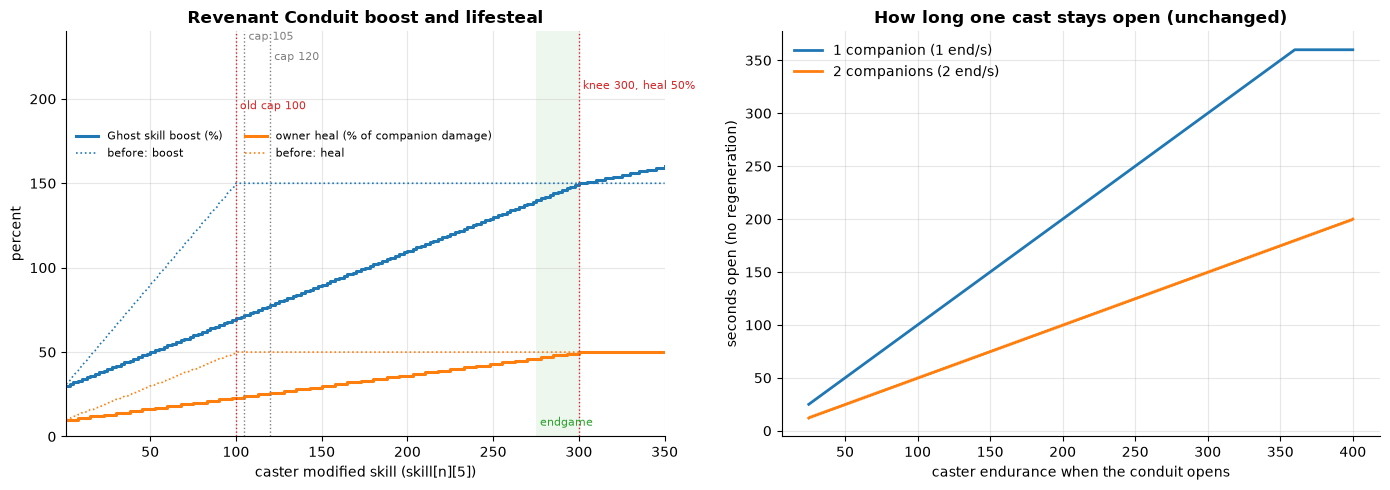

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

ax = axes[0]
line, = ax.step(P, boost_pct(P), where="post", lw=2.2, label="Ghost skill boost (%)")
ax.plot(P, old_boost_pct(P), color=line.get_color(), lw=1.2, ls=":", label="before: boost")
line, = ax.step(P, heal_pct(P), where="post", lw=2.2, label="owner heal (% of companion damage)")
ax.plot(P, old_heal_pct(P), color=line.get_color(), lw=1.2, ls=":", label="before: heal")
mm.skill_axis(ax, "percent", "Revenant Conduit boost and lifesteal")
mm.mark_caps(ax, extra=[(mm.SKILL_KNEE, "knee 300, heal 50%"), (100, "old cap 100")])
ax.set_ylim(0, 240)
ax.legend(loc="upper left", bbox_to_anchor=(0.0, 0.78), ncol=2, fontsize=8)

ax = axes[1]
END = np.arange(25, 401)
for n in (1, 2):
    ax.plot(END, open_seconds(END, n), label=f"{n} companion{'s' if n > 1 else ''} ({n} end/s)")
ax.set_xlabel("caster endurance when the conduit opens")
ax.set_ylabel("seconds open (no regeneration)")
ax.set_title("How long one cast stays open (unchanged)")
ax.legend()
plt.tight_layout()

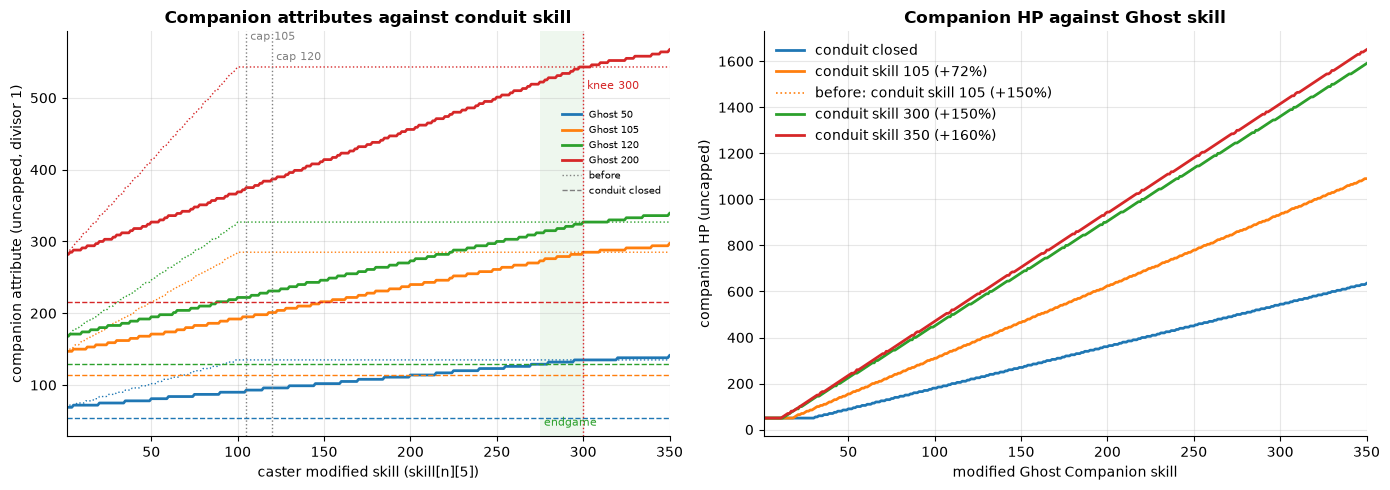

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

ax = axes[0]
for g in GHOST_SWEEP:
    line, = ax.plot(P, companion_attrib(companion_base(g, boost_pct(P))), label=f"Ghost {g}")
    ax.plot(P, companion_attrib(companion_base(g, old_boost_pct(P))), color=line.get_color(), lw=1, ls=":")
    ax.axhline(companion_attrib(companion_base(g)), color=line.get_color(), ls="--", lw=1)
ax.plot([], [], color="grey", lw=1, ls=":", label="before")
ax.plot([], [], color="grey", lw=1, ls="--", label="conduit closed")
mm.skill_axis(ax, "companion attribute (uncapped, divisor 1)",
              "Companion attributes against conduit skill")
mm.mark_caps(ax, extra=[(mm.SKILL_KNEE, "knee 300")])
ax.legend(loc="center right", bbox_to_anchor=(1.0, 0.7), fontsize=7)

ax = axes[1]
G = mm.SKILL_RANGE
for p in (0, 105, 300, 350):
    label = "conduit closed" if p == 0 else f"conduit skill {p} (+{int(boost_pct(p))}%)"
    b = companion_base(G) if p == 0 else companion_base(G, boost_pct(p))
    line, = ax.plot(G, companion_hp(b), label=label)
    if p == 105:
        ax.plot(G, companion_hp(companion_base(G, old_boost_pct(p))), color=line.get_color(),
                lw=1.2, ls=":", label=f"before: conduit skill {p} (+{int(old_boost_pct(p))}%)")
ax.set_xlabel("modified Ghost Companion skill")
ax.set_ylabel("companion HP (uncapped)")
ax.set_title("Companion HP against Ghost skill")
ax.set_xlim(G[0], G[-1])
ax.legend()
plt.tight_layout()

# Observations

- The boost climbs by 0.4% per skill point (heal about 0.13%) from +30% / 10% at skill 0 to
  +150% / 50% at modified skill 300. At the endgame (275–300) it is +140% to +150% with a 46–50%
  heal, so the old ceiling now needs a top-rank skill instead of skill 100.
- The mid-game is weaker. At the raise cap of 105 the boost is +72% with a 24% heal (before
  +150% / 50%), and +78% / 26% at 120. Low-skill casters lose too: +38% instead of +54% at skill
  20, and +50% instead of +90% at 50.
- Skill beyond 300 still adds +0.2% boost per point (+160% at 350, +180% at 450), but the heal
  stops at 50%.
- With Ghost 105 the companion has 114 attributes and 190 HP with the conduit closed. Open at
  skill 105 it has 195 attributes and 325 HP (before: 285 and 475). At skill 300 it has 285
  attributes and 475 HP, the old ceiling, and 297 / 495 at 350. With Ghost 120 the same steps are
  129 / 215 closed, 222 / 370 at 105, and 327 / 545 at 300.
- The template caps (`attrib[n][2]`, `skill[n][2]`, `hp[2]`) may cut this down. They live in the
  world snapshot, so check them before tuning. If they sit near the closed-conduit values, most of
  the boost is wasted and the lifesteal is the only part that matters. Above 300 the boost is
  unbounded, so the caps are the only limit there.
- Every HP a companion removes after armor heals the owner for up to half of it, with no cap other
  than the owner's max HP. Only player owners are healed.
- The drain is 1 endurance per second per live companion, counted on every tick. With Kindred
  Spirit's second ghost the conduit costs 2/s, and a full 360 s needs 720 endurance instead of
  360. With no companion it still drains 1/s. The lifesteal per companion is unchanged, so two
  companions heal twice as much at twice the upkeep.
- 17 mana opens it for up to 360 s. The 25-endurance gate is checked but never spent. The talent
  text ("at the cost of mana and a steady endurance drain") matches this.
- Closing it costs nothing and needs no endurance, and re-opening costs 17 mana with no cooldown.
  Companions are re-statted on every toggle, so the boost applies to ghosts that are already
  summoned.
- `clear_companion_dependent_buffs` removes it when the owner has no living companion, so a dead
  ghost forces a resummon (45 mana) and a recast.
- If two-companion lifesteal is still too strong at the endgame, the next step is decoupling the
  heal from the boost, for example `heal = clamp(p/6, 5, 50)`, stored on the marker alongside the
  boost.